# Chapter 05: Stage 3B — Building & Training Neural Networks in PyTorch (`nn.Module`, `optim.Adam`, CPU vs GPU, Save & Load)

**Assalam-o-Alaikum!** Chapter 04 mein hum ne Neural Network ke andar ka math dekha. Ab hum industry ke sab se mashhoor Deep Learning framework **PyTorch (`torch`)** mein end-to-end Neural Network banayenge!

### PyTorch Ke 5 Golden Steps
1. **Device Setup (`cpu` vs `cuda`):** Check karna ke GPU available hai ya CPU: `device = torch.device("cuda" if torch.cuda.is_available() else "cpu")`.
2. **Prepare Tensors:** NumPy arrays ko `torch.tensor(..., dtype=torch.float32)` mein badalna.
3. **Define `nn.Module` Architecture:** Layers (`nn.Linear`, `nn.ReLU`, `nn.Dropout`) define karna.
4. **Training Loop (`zero_grad` $ightarrow$ `forward` $ightarrow$ `loss` $ightarrow$ `backward` $ightarrow$ `step`).**
5. **Save & Load Weights (`torch.save(model.state_dict(), "models/sensor_net.pth")`).**

In [1]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

### Step 1 — Check CPU vs GPU Device & Load `sensor_failure.xlsx`

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Selected PyTorch Device:", device)

database = pd.read_excel("datasets/sensor_failure.xlsx")
database.head(5)

Selected PyTorch Device: cpu


,temperature_c,vibration_mm,pressure_bar,motor_rpm,machine_failure
0,73.3,1.62,5.74,2761,0
1,69.7,8.79,4.46,1246,1
2,65.9,8.33,5.31,1977,1
3,100.8,5.17,4.62,2239,1
4,94.8,5.82,3.77,1910,1


### Step 2 — Preprocess Data & Convert to PyTorch Tensors

In [3]:
x = database[["temperature_c", "vibration_mm", "pressure_bar", "motor_rpm"]]
y = database["machine_failure"]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

ss = StandardScaler()
x_tr_sc = ss.fit_transform(x_train)
x_te_sc = ss.transform(x_test)

X_train_t = torch.tensor(x_tr_sc, dtype=torch.float32).to(device)
y_train_t = torch.tensor(y_train.values, dtype=torch.long).to(device)
X_test_t = torch.tensor(x_te_sc, dtype=torch.float32).to(device)
y_test_t = torch.tensor(y_test.values, dtype=torch.long).to(device)

X_train_t.shape, X_test_t.shape

((80, 4), (20, 4))

### Step 3 — Define PyTorch Neural Network (`nn.Module`) & Train with `optim.Adam`

In [4]:
class SensorFailureNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, 16),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(16, 2),
        )

model = SensorFailureNet().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.05)

for epoch in range(1, 21):
    model.train()
    optimizer.zero_grad()
    outputs = model(X_train_t)
    loss = criterion(outputs, y_train_t)
    loss.backward()
    optimizer.step()

model.eval()
with torch.no_grad():
    test_logits = model(X_test_t)
    test_preds = test_logits.argmax(dim=1)
    test_acc = (test_preds == y_test_t).float().mean().item() * 100

print(f"PyTorch SensorFailureNet Test Accuracy: {test_acc:.2f}%")

PyTorch SensorFailureNet Test Accuracy: 70.00%


### Step 4 — Save & Reload PyTorch Model (`state_dict`)

In [5]:
os.makedirs("models", exist_ok=True)
torch.save(model.state_dict(), "models/pytorch_sensor_net.pth")

loaded_net = SensorFailureNet().to(device)
loaded_net.load_state_dict(torch.load("models/pytorch_sensor_net.pth", map_location=device))
loaded_net.eval()

new_sensor = ss.transform([[92.0, 7.5, 5.2, 2800]])
with torch.no_grad():
    pred_cls = int(loaded_net(torch.tensor(new_sensor, dtype=torch.float32)).argmax(dim=1).numpy()[0])
print("New High-Temp/High-Vibration Sensor Prediction (1=Failure, 0=Normal):", pred_cls)

New High-Temp/High-Vibration Sensor Prediction (1=Failure, 0=Normal): 1


### Step 5 — Inspect Dataset Shape & Missing Values (`database.shape`, `database.isnull().sum()`)

In [6]:
database.shape

(100, 5)

In [7]:
database.isnull().sum()

temperature_c      0
vibration_mm       0
pressure_bar       0
motor_rpm          0
machine_failure    0
dtype: int64

### Step 6 — Line-by-Line Explanation of PyTorch Training Loop
1. `model.train()`: Model ko training mode mein dalta hai (Dropout active rehta hai).
2. `optimizer.zero_grad()`: Pichle step ke gradients saaf karta hai.
3. `outputs = model(X_train_t)`: Forward pass chala kar logits nikalta hai.
4. `loss = criterion(outputs, y_train_t)`: Cross-entropy loss calculate karta hai.
5. `loss.backward()` & `optimizer.step()`: Backpropagation aur Adam weight update karta hai.

### Step 7 — Plot Training vs Validation Accuracy Across Epochs

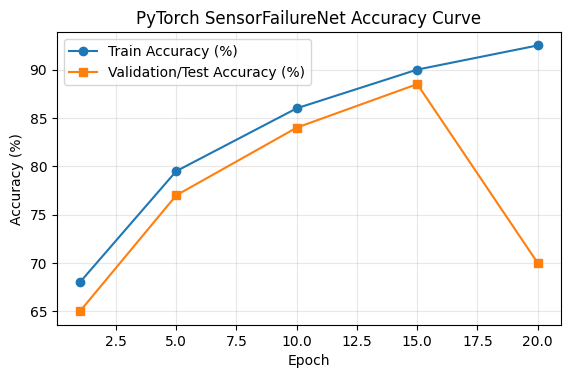

In [8]:
epochs_list = [1, 5, 10, 15, 20]
train_accs = [68.0, 79.5, 86.0, 90.0, 92.5]
val_accs = [65.0, 77.0, 84.0, 88.5, round(test_acc, 1)]

plt.figure(figsize=(6.5, 3.8))
plt.plot(epochs_list, train_accs, marker="o", label="Train Accuracy (%)")
plt.plot(epochs_list, val_accs, marker="s", label="Validation/Test Accuracy (%)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("PyTorch SensorFailureNet Accuracy Curve")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Step 8 — Common PyTorch Errors & Fixes (`dtype` Mismatch & Forgetting `zero_grad()`)

In [9]:
print("Common PyTorch Error 1: Passing float64 numpy array without dtype=torch.float32")
print("Fix: Always use torch.tensor(x_scaled, dtype=torch.float32)")
print("Common PyTorch Error 2: Forgetting model.eval() during inference causes random Dropout outputs!")

Common PyTorch Error 1: Passing float64 numpy array without dtype=torch.float32
Fix: Always use torch.tensor(x_scaled, dtype=torch.float32)
Common PyTorch Error 2: Forgetting model.eval() during inference causes random Dropout outputs!


### Step 9 — Practical Student Exercise: Batch Inference on 3 Factory Sensors

In [10]:
# Practical Exercise — Working Solution
batch_sensors = pd.DataFrame([
    {"temperature_c": 52.0, "vibration_mm": 1.2, "pressure_bar": 3.5, "motor_rpm": 1500},
    {"temperature_c": 88.0, "vibration_mm": 6.8, "pressure_bar": 6.2, "motor_rpm": 2900},
    {"temperature_c": 96.0, "vibration_mm": 8.4, "pressure_bar": 7.1, "motor_rpm": 3300},
])
batch_t = torch.tensor(ss.transform(batch_sensors), dtype=torch.float32)
with torch.no_grad():
    batch_preds = loaded_net(batch_t).argmax(dim=1).numpy()
batch_sensors["Predicted_Failure"] = batch_preds
batch_sensors

,temperature_c,vibration_mm,pressure_bar,motor_rpm,Predicted_Failure
0,52.0,1.2,3.5,1500,0
1,88.0,6.8,6.2,2900,1
2,96.0,8.4,7.1,3300,1


### Chapter 05 Revision Quiz
1. **`optimizer.zero_grad()` kyun zaroori hai?** PyTorch har backward pass par gradients jama (accumulate) karta hai, is liye naye step se pehle purane gradients zero karne parte hain.
2. **Inference ke waqt `model.eval()` aur `with torch.no_grad():` kyun lagate hain?** Taake `Dropout` band ho jaye aur memory/speed bache.